In [188]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve
import seaborn as sns

In [182]:
def H(u, k):
    return 1/(1 + np.e**(-100*(u - k)))

def W(x):
    return 2*np.sign(x)*(np.exp(-np.abs(x)/2) - np.exp(-np.abs(x)))

# define variables
dx = dt = 0.02
x = np.arange(-20, 20 + dx/2, dx)
N = len(x)
kappa = 0.3
t_end = 30
a_minus = -np.log(.5+np.sqrt(.4)/2)
a_plus = -np.log(.5-np.sqrt(.4)/2)

# define the weight function accords to the wizard hat
off = dx*np.arange(-(N-1), N)
wk = 2*np.exp(-np.abs(off)) - np.exp(-np.abs(off)/2)


# define how it progresses in time
def bump(u, k):
    steps = int(t_end/dt)
    bump_mat = np.zeros((steps+1, N))
    bump_mat[0,:] = u
    for s in range(steps):
        u_cur = bump_mat[s,:]
        conv = fftconvolve(H(u_cur,k), wk, mode="valid")*dx   # length N, aligned with x
        u_next = u_cur + dt*(-u_cur + conv)

        bump_mat[s+1,:] = u_next

    return bump_mat
def halfwidth_mat(mat, x, kappa):
    steps = mat.shape[0]
    hw = np.zeros(steps)
    for s in range(steps):
        pt = halfwidth(mat[s,:], x, kappa)
        hw[s] = pt

    return hw
    
def halfwidth(u, x, kappa):
    above = u > kappa
    if not above.any():
        return 0.0                      # bump has died
    idx = np.where(above)[0]
    i0, i1 = idx[0], idx[-1]
    # guard against the active region touching the domain edge
    if i0 == 0 or i1 == len(x) - 1:
        return np.nan
    # linear interpolation of the two kappa crossings
    xl = x[i0-1] + (x[i0]-x[i0-1])*(kappa-u[i0-1])/(u[i0]-u[i0-1])
    xr = x[i1]   + (x[i1+1]-x[i1])*(u[i1]-kappa)/(u[i1]-u[i1+1])
    return 0.5*(xr - xl)

In [158]:
init1 = W(x + (a_minus - .02)) - W(x - (a_minus - .02))
init2 = W(x + (a_minus + .02)) - W(x - (a_minus + .02))
init3 = W(x + (a_plus - .05)) - W(x - (a_plus - .05))
init4 = W(x + (a_plus + .05)) - W(x - (a_plus + .05))
t = np.linspace(0, 30, 1501)

In [184]:
test1 = bump(init1, .3)
hw1 = halfwidth_mat(test1, x, .3)

test2 = bump(init2, .3)
hw2 = halfwidth_mat(test2, x, .3)

test3 = bump(init3, .3)
hw3 = halfwidth_mat(test3, x, .3)

test4 = bump(init4, .3)
hw4 = halfwidth_mat(test4, x, .3)

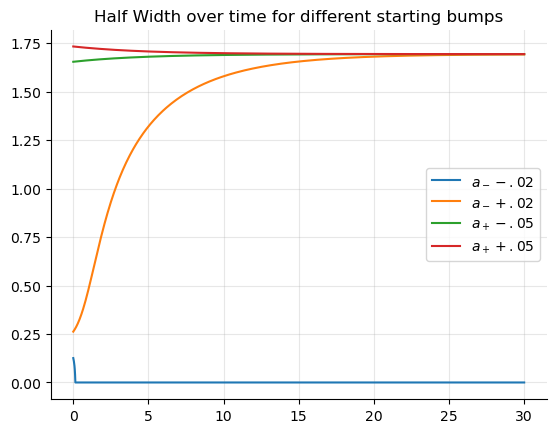

In [207]:
plt.plot(t, hw1, label = r"$a_- - .02$")
plt.plot(t, hw2, label = r"$a_- + .02$")
plt.plot(t, hw3, label = r"$a_+ - .05$")
plt.plot(t, hw4, label = r"$a_+ + .05$")
plt.legend()
plt.grid(alpha = .3)
sns.despine()
plt.title("Half Width over time for different starting bumps")
plt.savefig("halfwidth1", dpi = 300, bbox_inches = "tight")
plt.show()

Slope -0.10445870386278636
lambda_e 0.09016994374947425
Slope -0.17861751385491367
lambda_e 0.20825098524754793
Slope -0.2031431941227542
lambda_e 0.19513135728414577


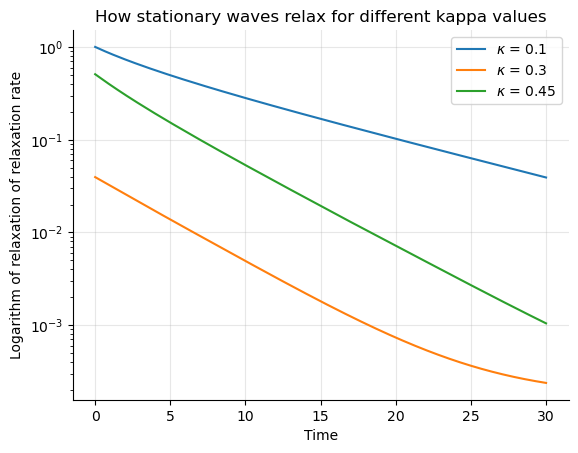

In [209]:
## part i)
kappa_lst = [.1, .3, .45]
for k in range(3):
    kappa = kappa_lst[k]
    s = np.sqrt(1 - 2*kappa)
    a_p = -np.log(.5 - s/2)
    lambda_e = s*(1-s)/(1 + s*(1-s)/2)
    sim = bump(init4, kappa)
    hw_list = halfwidth_mat(sim, x, kappa)
    dev = np.abs(hw_list - a_p)
    plt.semilogy(t, dev, label = r"$\kappa$ = " + str(kappa))
    slope, intercept = np.polyfit(t, np.log(dev), 1)
    print("Slope", slope)
    print("lambda_e", lambda_e)
plt.legend()
plt.grid(alpha = .3)
sns.despine()
plt.xlabel("Time")
plt.ylabel("Logarithm of relaxation of relaxation rate")
plt.title("How stationary waves relax for different kappa values")
plt.savefig("halfwidth2", dpi = 300, bbox_inches = "tight")
plt.show()